# Time-Based Data Split (Slide Graphic)

This notebook creates a presentation-ready graphic that combines:
- chronological data split (Train/Test)
- percentages by year
- short split notes

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# ---- Configure your split here ----
# Values represent percentages within each year (0-100).
# The remaining share (if below 100) is shown as "Unused" in gray.
# Current project setup (verified): Train <= 2022, Test >= 2023.
years = list(range(2007, 2026))
split_table = pd.DataFrame({
    "year": years,
    "train_pct": [10 if y <= 2022 else 0 for y in years],
    "val_pct": [0 for _ in years],
    "test_pct": [10 if y >= 2023 else 0 for y in years],
})

# Optional labels for split lines (between years).
split_1_after_year = 2022
split_2_after_year = None

# Short split notes shown directly in the graphic.
split_notes = [
    "Temporal holdout: Train <= 2022, Test >= 2023",
    "Best hyperparameters imported from Notebook 06",
    "Final metrics on unseen years 2023-2025",
]

# Export path for PowerPoint use (robust for root or notebooks cwd).
cwd = Path.cwd()
project_root = cwd if (cwd / "data").exists() else cwd.parent
export_path = project_root / "data" / "plots" / "time_split_validation_strategy.png"
export_path.parent.mkdir(parents=True, exist_ok=True)

In [5]:
# Basic data checks
required_cols = {"year", "train_pct", "val_pct", "test_pct"}
missing_cols = required_cols - set(split_table.columns)
if missing_cols:
    raise ValueError(f"Missing columns: {sorted(missing_cols)}")

split_table = split_table.sort_values("year").reset_index(drop=True)
row_sums = split_table[["train_pct", "val_pct", "test_pct"]].sum(axis=1)

if (row_sums > 100).any():
    bad_years = split_table.loc[row_sums > 100, "year"].tolist()
    raise ValueError(f"Assigned shares exceed 100% in years: {bad_years}")

split_table["unused_pct"] = 100 - row_sums
split_table

,year,train_pct,val_pct,test_pct,unused_pct
0,2007,10,0,0,90
1,2008,10,0,0,90
2,2009,10,0,0,90
3,2010,10,0,0,90
4,2011,10,0,0,90
5,2012,10,0,0,90
6,2013,10,0,0,90
7,2014,10,0,0,90
8,2015,10,0,0,90
9,2016,10,0,0,90


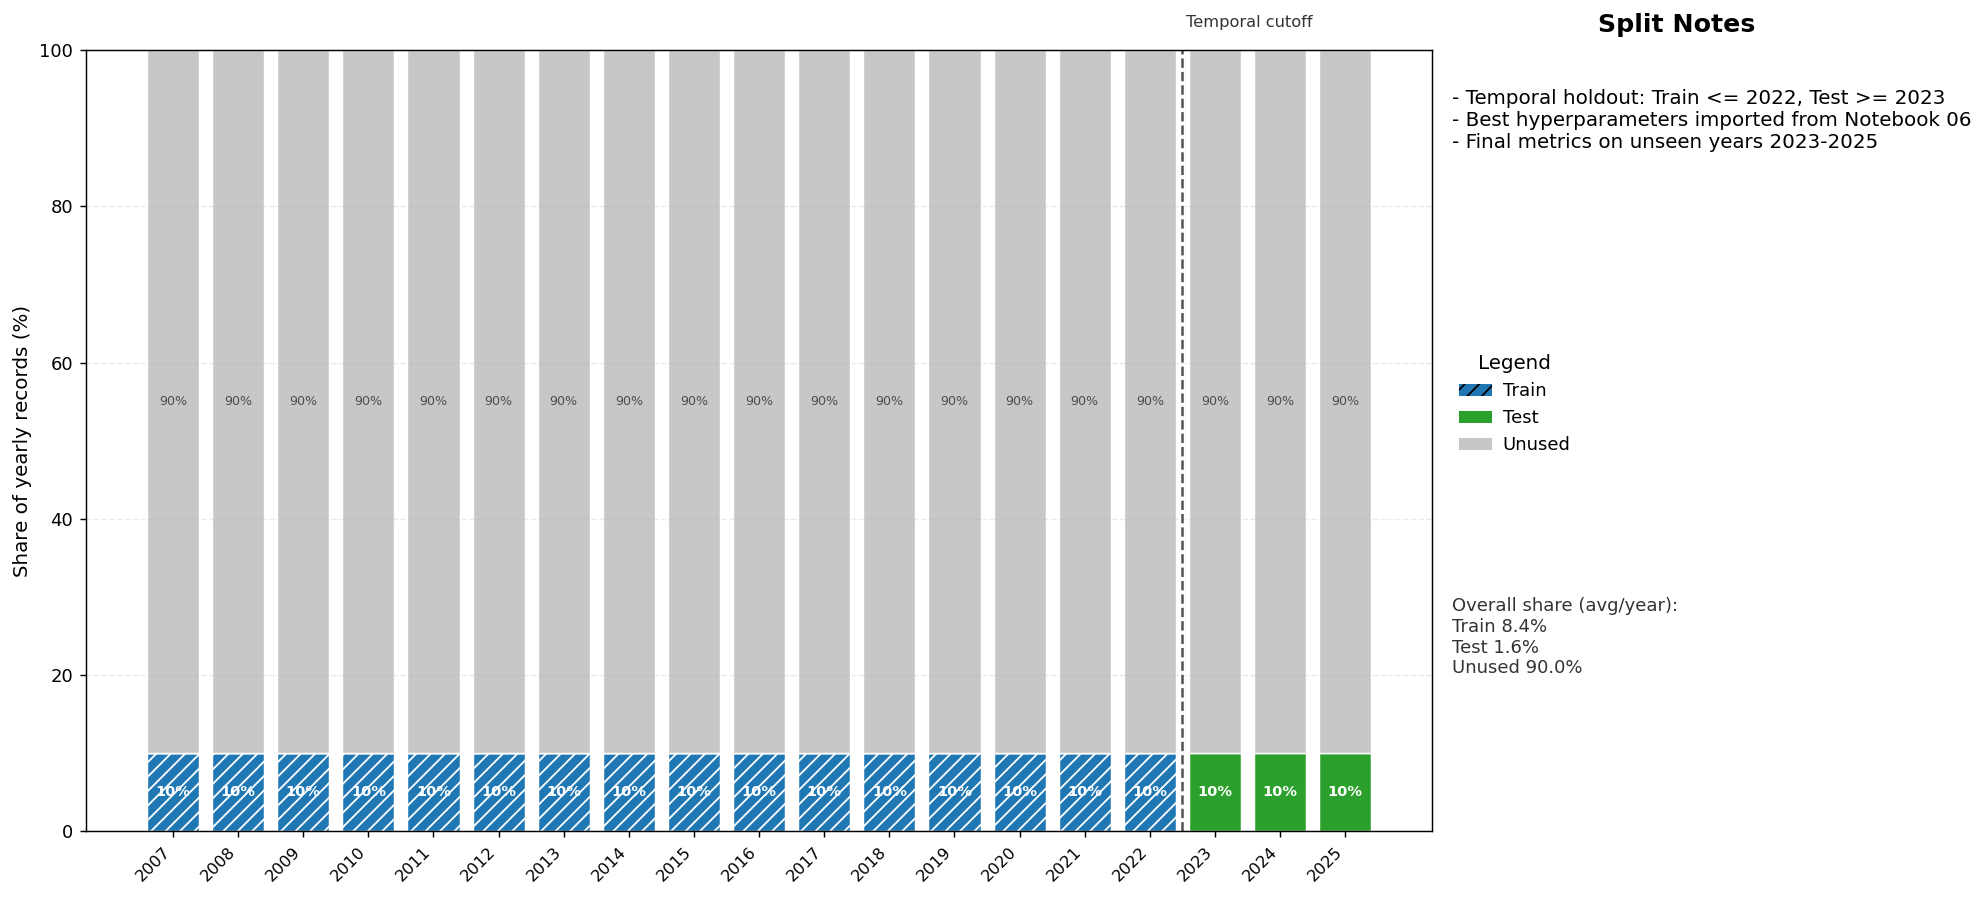

Saved slide graphic to: <project-root>\\data\plots\time_split_validation_strategy.png


In [6]:
# Build a clean, slide-friendly figure for the time-based split.
colors = {
    "train_pct": "#1f77b4",
    "val_pct": "#ff7f0e",
    "test_pct": "#2ca02c",
    "unused_pct": "#c7c7c7",
}

fig = plt.figure(figsize=(16, 7), dpi=130)
gs = fig.add_gridspec(1, 2, width_ratios=[3.6, 1.2])
ax = fig.add_subplot(gs[0, 0])
ax_notes = fig.add_subplot(gs[0, 1])

x = range(len(split_table))
bottom = [0] * len(split_table)

ax.bar(
    x,
    split_table["train_pct"],
    bottom=bottom,
    color=colors["train_pct"],
    edgecolor="white",
    linewidth=0.8,
    hatch="///",
)
bottom = [b + v for b, v in zip(bottom, split_table["train_pct"])]

for col in ["val_pct", "test_pct", "unused_pct"]:
    ax.bar(x, split_table[col], bottom=bottom, color=colors[col], edgecolor="white", linewidth=0.8)
    bottom = [b + v for b, v in zip(bottom, split_table[col])]

ax.set_ylabel("Share of yearly records (%)", fontsize=11)
ax.set_ylim(0, 100)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_xticks(list(x))
ax.set_xticklabels(split_table["year"].astype(str).tolist(), fontsize=9, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25, linestyle="--")

# Add percentage labels for used shares; add small gray labels for unused share.
for i, row in split_table.iterrows():
    cumulative = 0
    for col in ["train_pct", "test_pct"]:
        v = row[col]
        if v > 0:
            ax.text(i, cumulative + v / 2, f"{int(v)}%", ha="center", va="center", fontsize=8, color="white", weight="bold")
        cumulative += v

    cumulative += row["val_pct"]

    unused_v = row["unused_pct"]
    if unused_v > 0:
        ax.text(i, cumulative + unused_v / 2, f"{int(unused_v)}%", ha="center", va="center", fontsize=7, color="#4d4d4d")

# Split line based on year boundary
years = split_table["year"].tolist()
if split_1_after_year in years:
    i1 = years.index(split_1_after_year)
    ax.axvline(i1 + 0.5, color="#555555", linestyle="--", linewidth=1.4)
    ax.text(i1 + 0.55, 103, "Temporal cutoff", fontsize=9, color="#333333")
if split_2_after_year in years:
    i2 = years.index(split_2_after_year)
    ax.axvline(i2 + 0.5, color="#555555", linestyle="--", linewidth=1.4)

legend_handles = [
    Patch(facecolor=colors["train_pct"], hatch="///", label="Train"),
    Patch(facecolor=colors["test_pct"], label="Test"),
    Patch(facecolor=colors["unused_pct"], label="Unused"),
]

# Notes panel
ax_notes.axis("off")
ax_notes.set_title("Split Notes", fontsize=14, weight="bold", pad=10)
notes_text = "\n".join([f"- {n}" for n in split_notes])
ax_notes.text(0.0, 0.95, notes_text, va="top", fontsize=11)

# Move legend to the right panel between notes and summary.
ax_notes.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.0, 0.62),
    frameon=False,
    ncol=1,
    title="Legend",
    title_fontsize=11,
    fontsize=10,
    borderaxespad=0.0,
    handlelength=1.8,
    handletextpad=0.6,
)

# Overall average shares per year
overall = split_table[["train_pct", "test_pct", "unused_pct"]].mean().round(1)
summary = (
    f"Overall share (avg/year):\n"
    f"Train {overall['train_pct']}%\n"
    f"Test {overall['test_pct']}%\n"
    f"Unused {overall['unused_pct']}%"
)
ax_notes.text(0.0, 0.30, summary, va="top", fontsize=10, color="#333333")

plt.tight_layout()
plt.savefig(export_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved slide graphic to: {export_path}")

## Optional: derive split table from a real date column

If you already have a dataframe with a date column, this helper builds the yearly split table automatically based on two split dates.

In [7]:
def build_split_table_from_dates(df, date_col, split_1, split_2):
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    out['year'] = out[date_col].dt.year

    def assign_set(d):
        if d <= pd.Timestamp(split_1):
            return 'train'
        if d <= pd.Timestamp(split_2):
            return 'val'
        return 'test'

    out['set'] = out[date_col].map(assign_set)

    ctab = pd.crosstab(out['year'], out['set'], normalize='index') * 100
    ctab = ctab.rename(columns={'train': 'train_pct', 'val': 'val_pct', 'test': 'test_pct'})
    for col in ['train_pct', 'val_pct', 'test_pct']:
        if col not in ctab.columns:
            ctab[col] = 0.0

    return ctab.reset_index()[['year', 'train_pct', 'val_pct', 'test_pct']]

# Example usage (uncomment and adapt):
# df = pd.read_csv('data/processed/your_dataset.csv')
# split_table = build_split_table_from_dates(df, date_col='date', split_1='2021-12-31', split_2='2022-12-31')
# split_table